# Simulation de l’évolution du marché du travail

Ce projet a pour objectif de proposer une **simulation simplifiée du marché du travail** sur une période de **20 ans**, en s’appuyant sur des notions de programmation vues en travaux pratiques.

Le modèle repose sur la représentation d’**individus** et d’**entreprises**, ainsi que sur des règles simples permettant de faire évoluer l’emploi, le chômage et les offres d’emploi au fil du temps.

L’objectif n’est pas de reproduire fidèlement la réalité économique, mais de mettre en place un **modèle cohérent et interprétable**, permettant d’analyser des tendances générales à l’aide de simulations et de représentations graphiques.


# 🔹 Données initiales (année de référence)


## Données initiales des individus

Dans cette première étape, nous générons une **population initiale d’individus** représentant le marché du travail pour une année de référence.

Les données sont générées numériquement afin d’obtenir des **ordres de grandeur cohérents**, sans chercher à reproduire fidèlement la réalité.

Chaque individu est représenté par un dictionnaire contenant :
- `id` : un identifiant unique
- `E` : un booléen indiquant si la personne est **employée** ou non
- `nbAnneeExp` : le nombre d’**années d’expérience professionnelle**

La population totale est composée de `N` individus.  
Une partie de la population est initialement fixée comme **non employée**, une autre comme **employée**.
Cette population constitue le **point de départ** notre simulation.


In [1]:
import matplotlib.pyplot as plt
import random
random.seed(42)

N = 30532
n_notE = 4018
n_E = 26514
assert n_E + n_notE == N
individus = []
id_counter = 1
for _ in range(n_notE):
    individus.append({
        "id": id_counter,
        "E": False,
        "nbAnneeExp":random.randint(0,5)})
    id_counter += 1

for _ in range(n_E):
    individus.append({
        "id": id_counter,
        "E": True,
        "nbAnneeExp":random.randint(0,11)})
    id_counter += 1

## Données relatives aux entreprises

Nous définissons ensuite un ensemble d’**entreprises**, réparties selon différents secteurs d’activité :
- `AGR`: agriculture,
- `IND`: industrie,
- `CON`: construction,
- `TER`: tertiaire.

Chaque entreprise est décrite par :
- `id`: un identifiant,
- `Sec`: un secteur d’activité,
- `NbSalarie`: un nombre de salariés.

Ces données constituent la base de la modélisation de l’offre d’emploi dans la simulation et sont stockées dans une liste de dictionnaires notée: `dataEntr` .


In [2]:
dataEntr = [
    # Agriculture
    {'id': 'InVivo', 'Sec': 'AGR', 'NbSalarie': 27},
    {'id': 'Groupe Avril', 'Sec': 'AGR', 'NbSalarie': 26},
    {'id': 'Terrena', 'Sec': 'AGR', 'NbSalarie': 32},
    {'id': 'Limagrain', 'Sec': 'AGR', 'NbSalarie': 16},
    {'id': 'Soufflet Agriculture', 'Sec': 'AGR', 'NbSalarie': 33},
    {'id': 'Tereos', 'Sec': 'AGR', 'NbSalarie': 28},
    {'id': 'Agrial', 'Sec': 'AGR', 'NbSalarie': 25},
    {'id': 'Bonduelle', 'Sec': 'AGR', 'NbSalarie': 23},
    {'id': 'Coopérative Océalia', 'Sec': 'AGR', 'NbSalarie': 33},
    {'id': 'AgroNova', 'Sec': 'AGR', 'NbSalarie': 28},
    # Construction
    {'id': 'Vinci Construction', 'Sec': 'CON', 'NbSalarie': 34},
    {'id': 'Bouygues Travaux Publics', 'Sec': 'CON', 'NbSalarie': 88},
    {'id': 'Eiffage Construction', 'Sec': 'CON', 'NbSalarie': 180},
    {'id': 'Colas', 'Sec': 'CON', 'NbSalarie': 386},
    {'id': 'Spie Batignolles', 'Sec': 'CON', 'NbSalarie': 539},
    {'id': 'Léon Grosse', 'Sec': 'CON', 'NbSalarie': 668},
    {'id': 'NGE', 'Sec': 'CON', 'NbSalarie': 563},
    {'id': 'Fayat', 'Sec': 'CON', 'NbSalarie': 373},
    {'id': 'Demathieu Bard', 'Sec': 'CON', 'NbSalarie': 232},
    {'id': 'Construxia', 'Sec': 'CON', 'NbSalarie': 131},
    # Industrie
    {'id': 'Renault', 'Sec': 'IND', 'NbSalarie': 604},
    {'id': 'Stellantis', 'Sec': 'IND', 'NbSalarie': 400},
    {'id': 'Airbus', 'Sec': 'IND', 'NbSalarie': 231},
    {'id': 'Safran', 'Sec': 'IND', 'NbSalarie': 119},
    {'id': 'ArcelorMittal', 'Sec': 'IND', 'NbSalarie': 86},
    {'id': 'Michelin', 'Sec': 'IND', 'NbSalarie': 52},
    {'id': 'Saint-Gobain', 'Sec': 'IND', 'NbSalarie': 29},
    {'id': 'TotalEnergies', 'Sec': 'IND', 'NbSalarie': 21},
    {'id': 'Alstom', 'Sec': 'IND', 'NbSalarie': 5},
    {'id': 'Mécafrance Industrie', 'Sec': 'IND', 'NbSalarie': 21},
    # Tertiaire
    {'id': 'BNP Paribas', 'Sec': 'TER', 'NbSalarie': 93},
    {'id': 'Société Générale', 'Sec': 'TER', 'NbSalarie': 692},
    {'id': 'Capgemini', 'Sec': 'TER', 'NbSalarie': 1363},
    {'id': 'Orange', 'Sec': 'TER', 'NbSalarie': 2092},
    {'id': 'Accor', 'Sec': 'TER', 'NbSalarie': 2662},
    {'id': 'Carrefour', 'Sec': 'TER', 'NbSalarie': 3420},
    {'id': 'La Poste', 'Sec': 'TER', 'NbSalarie': 4032},
    {'id': 'AXA', 'Sec': 'TER', 'NbSalarie': 4500},
    {'id': 'Dassault Systèmes', 'Sec': 'TER', 'NbSalarie': 2346},
    {'id': 'DataLink Consulting', 'Sec': 'TER', 'NbSalarie': 281},
]

Pour obtenir le nombre de salariés:

In [3]:
assert sum(e["NbSalarie"] for e in dataEntr) == n_E

## Classe Personne

La classe `Personne` permet de représenter un individu de la population étudiée.

Chaque instance correspond à une personne caractérisée par :
- `id`: un identifiant,
- `E`: un statut d’emploi,
- `nbAnneeExp`: un nombre d’années d’expérience professionnelle.

Un attribut supplémentaire permet de stocker l’entreprise à laquelle la personne est rattachée, noté : `entreprise`. 
Cet attribut est initialisé à `None` et sera renseigné au cours de la simulation.

La classe contient également un attribut de classe permettant de suivre le nombre total de personnes créées.


In [4]:
class Personne:
    nbPersActiv = 0

    def __init__(self, identifiant, E,nbAnneeExp):
        self.id = identifiant
        self.E = E
        self.nbAnneeExp=nbAnneeExp
        self.entreprise=None
        Personne.nbPersActiv+=1        

    def __str__(self):
        tmp = f" Personne {self.id}"
        if  self.E:
            tmp+=" est employée"
        else:
            tmp+=" n'est pas employée"
        return tmp +f" , à {self.nbAnneeExp} année d'expérience"

## Création de la population d’objets Personne

À partir des données initiales, les individus sont transformés en **objets de la classe `Personne`**.

Cette étape permet de passer d’une représentation sous forme de dictionnaires à une représentation orientée objet, facilitant les évolutions ultérieures de la simulation.

Quelques individus sont affichés afin de vérifier que la création des objets s’est correctement déroulée.


In [5]:
personnes = [Personne(i["id"], i["E"], i["nbAnneeExp"]) for i in individus]

assert Personne.nbPersActiv == N

for p in random.sample(personnes, 10):
    print(p)

 Personne 26010 est employée , à 6 année d'expérience
 Personne 15658 est employée , à 7 année d'expérience
 Personne 4423 est employée , à 5 année d'expérience
 Personne 13256 est employée , à 2 année d'expérience
 Personne 25839 est employée , à 9 année d'expérience
 Personne 5633 est employée , à 11 année d'expérience
 Personne 590 n'est pas employée , à 2 année d'expérience
 Personne 24238 est employée , à 0 année d'expérience
 Personne 16644 est employée , à 6 année d'expérience
 Personne 8721 est employée , à 11 année d'expérience


## Classe `Entreprise`

La classe `Entreprise` permet de représenter une entreprise du marché du travail.

Chaque entreprise est définie par :
- son **identifiant** ('`id`),
- son **secteur d’activité** (`AGR`, `IND`, `CON`, `TER`),
- son **nombre de salariés**(`NbSalarie`).

Des compteurs globaux permettent également de suivre le **nombre total de salariés par secteur** au cours de la simulation.

Deux dictionnaires sont utilisés pour paramétrer le comportement des entreprises :
- `COEFF_SECTEUR` : coefficient associé à chaque secteur, représentant le **niveau d’ouverture de postes** (secteurs plus ou moins dynamiques).
- `EXPERIENCE_MIN` : expérience minimale demandée pour être recruté dans un secteur, ce qui permet de modéliser des secteurs plus ou moins **exigeants**.

Des méthodes sont définies afin de faire évoluer les effectifs des entreprises, notamment lors des **embauches** et des **départs**.  
Enfin, le nombre d’offres d’emploi proposées par une entreprise dépend du secteur (via `COEFF_SECTEUR`) et de la taille de l'entreprise et peut varier au cours du temps en fonction de la situation économique simulée. 


In [6]:
# Part de l'effectif ouverte en offres chaque année, par secteur
COEFF_SECTEUR = {
    "AGR": 0.03,  # agriculture : peu de recrutements
    "IND": 0.05,  # industrie
    "CON": 0.07,  # construction
    "TER": 0.10,  # tertiaire : très dynamique
}

# Expérience minimale (en années) exigée pour être recruté, par secteur
EXPERIENCE_MIN = {
    "AGR": 0,  # accessible sans expérience
    "IND": 1,  # industrie
    "CON": 2,  # construction
    "TER": 3,  # tertiaire : plus exigeant
}

NOMS_SECTEUR = {
    "AGR": "de l'agriculture",
    "IND": "de l'industrie",
    "CON": "de la construction",
    "TER": "du tertiaire",
}


class Entreprise:
    # Attribut de classe : effectif total par secteur, partagé par toutes les entreprises
    nbsalarie_par_secteur = {"AGR": 0, "IND": 0, "CON": 0, "TER": 0}

    def __init__(self, identifiant, sec, nbsalarie):
        self.id = identifiant
        self.sec = sec
        self.nbsalarie = nbsalarie
        self.nboffre = int(nbsalarie * COEFF_SECTEUR[sec])
        Entreprise.nbsalarie_par_secteur[sec] += nbsalarie

    def embauche(self, nb_embauches):
        self.nbsalarie += nb_embauches
        Entreprise.nbsalarie_par_secteur[self.sec] += nb_embauches

    def depart(self, nb_departs):
        self.nbsalarie -= nb_departs
        Entreprise.nbsalarie_par_secteur[self.sec] -= nb_departs
        assert self.nbsalarie >= 0, f"Effectif négatif pour {self.id}"

    def __str__(self):
        return (f"Entreprise {NOMS_SECTEUR[self.sec]} : {self.id}, "
                f"possède {self.nbsalarie} salariés et {self.nboffre} offres")

## Création des objets Entreprise

Les données des entreprises sont transformées en **objets de la classe `Entreprise`**.

Cette étape permet de manipuler directement les entreprises dans la simulation et de suivre l’évolution de leurs effectifs et de leurs offres d’emploi.

Quelques entreprises sont affichées afin de vérifier le bon fonctionnement de la classe.


In [7]:
entreprises = [Entreprise(d["id"], d["Sec"], d["NbSalarie"]) for d in dataEntr]

for e in random.sample(entreprises, 10):
    print(e)

Entreprise de l'industrie : Michelin, possède 52 salariés et 2 offres
Entreprise du tertiaire : BNP Paribas, possède 93 salariés et 9 offres
Entreprise de l'agriculture : Coopérative Océalia, possède 33 salariés et 0 offres
Entreprise de la construction : Vinci Construction, possède 34 salariés et 2 offres
Entreprise de l'industrie : Safran, possède 119 salariés et 5 offres
Entreprise de la construction : Construxia, possède 131 salariés et 9 offres
Entreprise de la construction : Colas, possède 386 salariés et 27 offres
Entreprise de l'industrie : Renault, possède 604 salariés et 30 offres
Entreprise du tertiaire : Carrefour, possède 3420 salariés et 342 offres
Entreprise de l'agriculture : Terrena, possède 32 salariés et 0 offres


## Affectation initiale des employés aux entreprises

Les personnes déjà employées dans la population initiale sont affectées à des entreprises de manière aléatoire, en tenant compte de la taille des entreprises.

Cette étape permet d’obtenir une **répartition initiale cohérente des salariés**, avant le lancement de la simulation dynamique.


In [8]:

def initialiser_affectation(population, entreprises):
    employes = [p for p in population if p.E]
    random.shuffle(employes)  # mélange pour une affectation aléatoire

    # Les effectifs des entreprises doivent correspondre au nombre d'employés
    assert sum(e.nbsalarie for e in entreprises) == len(employes)

    i = 0
    for entreprise in entreprises:
        for _ in range(entreprise.nbsalarie):
            employes[i].entreprise = entreprise.id
            i += 1


In [9]:
initialiser_affectation(personnes, entreprises)

# Contrôle : toute personne employée a une entreprise, et inversement
assert all((p.entreprise is not None) == p.E for p in personnes)

for p in random.sample(personnes, 10):
    print(p, ":", p.entreprise or "Aucune")

 Personne 13004 est employée , à 4 année d'expérience : Capgemini
 Personne 12240 est employée , à 1 année d'expérience : Accor
 Personne 26902 est employée , à 3 année d'expérience : La Poste
 Personne 25367 est employée , à 6 année d'expérience : Carrefour
 Personne 29524 est employée , à 8 année d'expérience : Carrefour
 Personne 13103 est employée , à 2 année d'expérience : La Poste
 Personne 18664 est employée , à 6 année d'expérience : Accor
 Personne 29054 est employée , à 3 année d'expérience : Accor
 Personne 3474 n'est pas employée , à 3 année d'expérience : Aucune
 Personne 1503 n'est pas employée , à 0 année d'expérience : Aucune


## Mise en place de la simulation

Après avoir défini les individus et les entreprises, nous mettons en place les fonctions nécessaires à la simulation du marché du travail.

Ces fonctions permettent notamment :
- l’ouverture de postes par les entreprises,
- la publication des offres d’emploi,
- les candidatures des individus,
- les embauches et les départs.

Elles constituent les mécanismes fondamentaux permettant de faire évoluer l’emploi et le chômage au fil du temps.


## Ouverture des postes

Cette fonction permet de déterminer le **nombre de postes ouverts** par une entreprise pour une année donnée.

Ce nombre dépend du **secteur d’activité** de l’entreprise et d’un **facteur économique annuel**, ce qui permet de modéliser des périodes plus ou moins favorables à l’emploi.


In [10]:
def ouvrir_postes(entreprise, facteur):
    coeff = COEFF_SECTEUR[entreprise.sec]
    entreprise.nboffre= int(entreprise.nbsalarie * coeff * facteur)

## Classe `OffreEmploi`

La classe `OffreEmploi` représente une **offre d’emploi** proposée par une entreprise.

Chaque offre est associée à une entreprise et à un **secteur d’activité**, et comporte un **niveau minimal d’expérience requis** pour le recrutement.


In [11]:
class OffreEmploi:
    def __init__(self, entreprise):
        self.entreprise = entreprise
        self.secteur = entreprise.sec
        self.exp_min = EXPERIENCE_MIN[entreprise.sec]

## Publication des offres

Cette fonction permet de **générer l’ensemble des offres d’emploi** proposées par les entreprises pour une année donnée.



In [12]:
def publier_offres(entreprises):
    offres = []
    for entreprise in entreprises:
        for _ in range(entreprise.nboffre):
            offres.append(OffreEmploi(entreprise))
    return offres

## Candidature à une offre

Cette fonction modélise la **candidature d’un individu** à une offre d’emploi.

Une personne non employée peut candidater à une **unique** offre compatible avec son **niveau d’expérience** **(afin de simplifier notre projet**)), ce qui peut conduire à une embauche.


In [13]:
def postuler(personne, offres):
    if personne.E:
        return False

    offres_possibles = [o for o in offres if personne.nbAnneeExp >= o.exp_min]
    if not offres_possibles:
        return False

    offre = random.choice(offres_possibles)  # une seule candidature par personne
    if recruter(offre.entreprise, personne):
        offres.remove(offre)  # l'offre pourvue n'est plus disponible
        return True
    return False

## Recrutement

Cette fonction permet de modéliser le **recrutement d’un individu** par une entreprise.

Le recrutement est conditionné par la **disponibilité d’une offre** et par le **niveau d’expérience requis** pour le secteur concerné, et entraîne la mise à jour du statut de l’individu.


In [14]:
def recruter(entreprise, personne):
    if entreprise.nboffre <= 0 or personne.E:
        return False
    if personne.nbAnneeExp < EXPERIENCE_MIN[entreprise.sec]:
        return False

    entreprise.nboffre -= 1
    entreprise.embauche(1)  # l'effectif augmente seulement en cas de recrutement réel
    personne.E = True
    personne.entreprise = entreprise.id
    return True


## Départ d’une entreprise

Cette fonction modélise le **départ d’un individu de son entreprise**.

Elle entraîne la mise à jour du **statut d’emploi** de la personne ainsi que des **effectifs de l’entreprise**, permettant de représenter les sorties d’emploi au cours de la simulation.


In [15]:
entreprises_par_id = {e.id: e for e in entreprises}

def quitter(personne, entreprises_par_id):
    if not personne.E:
        return False

    entreprises_par_id[personne.entreprise].depart(1)
    personne.E = False
    personne.entreprise = None
    return True


## Historique de la simulation

Cette structure permet de **stocker les indicateurs globaux** de la simulation année par année.

Elle conserve notamment l’évolution du nombre d’employés, de chômeurs, du nombre d’offres d’emploi ainsi que la **répartition des emplois par secteur d’activité**, afin de faciliter l’analyse et la visualisation des résultats.


## Historique des entreprises

Cette structure permet de **stocker l’évolution individuelle des entreprises** au cours de la simulation.

Pour chaque entreprise, sont enregistrés le **nombre de salariés** et le **nombre d’offres d’emploi**, afin d’analyser leur comportement et leur évolution au fil du temps.


In [16]:
def creer_historiques(entreprises):
    historique = {
        "annee": [],
        "nb_employes": [],
        "nb_chomeurs": [],
        "nb_offres": [],
        "emplois_par_secteur": {sec: [] for sec in COEFF_SECTEUR},
    }
    historique_entreprises = {e.id: {"nbsalarie": [], "nboffre": []} for e in entreprises}
    historique_personne = {"annee": [], "employe": [], "experience": [], "entreprise": []}
    return historique, historique_entreprises, historique_personne

historique, historique_entreprises, historique_personne = creer_historiques(entreprises)


## Suivi du parcours individuel d’une personne

Cette fonction permet de suivre l’évolution d’une **personne identifiée par son identifiant** au cours de la simulation.

Pour chaque année, elle enregistre :
- l’année de la simulation,
- le **statut d’emploi** de la personne,
- son **nombre d’années d’expérience**,
- l’**entreprise** à laquelle elle est rattachée, le cas échéant.

Les informations sont stockées dans une structure dédiée afin de pouvoir visualiser et analyser le **parcours professionnel individuel** d’une personne sur l’ensemble des 20 années simulées.


In [17]:
def suivre_personne(personne, historique_personne, annee):
    historique_personne["annee"].append(annee)
    historique_personne["employe"].append(int(personne.E))
    historique_personne["experience"].append(personne.nbAnneeExp)
    historique_personne["entreprise"].append(personne.entreprise or "Aucune")


## Simulation d’une année du marché du travail

Une fonction centrale permet de simuler le déroulement d’une **année complète**.

Au cours d’une année :
- les entreprises ouvrent des postes,
- les offres d’emploi sont publiées,
- les individus peuvent candidater,
- des départs peuvent avoir lieu.

À la fin de chaque année, les indicateurs principaux du marché du travail sont calculés et enregistrés.


In [18]:
def enregistrer_annee(annee, individus, entreprises, nb_offres,
                      historique, historique_entreprises):
    nb_employes = sum(p.E for p in individus)
    historique["annee"].append(annee)
    historique["nb_employes"].append(nb_employes)
    historique["nb_chomeurs"].append(len(individus) - nb_employes)
    historique["nb_offres"].append(nb_offres)
    for sec in historique["emplois_par_secteur"]:
        historique["emplois_par_secteur"][sec].append(Entreprise.nbsalarie_par_secteur[sec])
    for e in entreprises:
        historique_entreprises[e.id]["nbsalarie"].append(e.nbsalarie)
        historique_entreprises[e.id]["nboffre"].append(e.nboffre)


def simulation_annee(individus, entreprises, entreprises_par_id, facteur, annee,
                     historique, historique_entreprises):
    # 1. Ouverture des postes selon la conjoncture
    for entreprise in entreprises:
        ouvrir_postes(entreprise, facteur)
    nb_offres = sum(e.nboffre for e in entreprises)

    # 2. Candidatures des chômeurs, dans un ordre aléatoire
    offres = publier_offres(entreprises)
    chomeurs = [p for p in individus if not p.E]
    random.shuffle(chomeurs)
    for personne in chomeurs:
        postuler(personne, offres)

    # 3. Départs : taux de base de 5 %, jusqu'à 15 % en crise forte (facteur proche de 0)
    taux_depart = 0.05 + (1 - facteur) * 0.10
    employes_par_entreprise = {e.id: [] for e in entreprises}
    for p in individus:
        if p.E:
            employes_par_entreprise[p.entreprise].append(p)
    for id_entreprise, employes in employes_par_entreprise.items():
        nb_departs = int(len(employes) * taux_depart)
        for p in random.sample(employes, nb_departs):
            quitter(p, entreprises_par_id)

    # 4. Les personnes employées gagnent un an d'expérience
    for personne in individus:
        if personne.E:
            personne.nbAnneeExp += 1

    # 5. Enregistrement des indicateurs
    enregistrer_annee(annee, individus, entreprises, nb_offres,
                      historique, historique_entreprises)

## Simulation sur 20 ans

La simulation est ensuite exécutée sur une période de **20 ans**.

Un facteur économique annuel est introduit afin de représenter une évolution progressive de la conjoncture économique.  
**plus le facteur est proche de 0, plus l'économie est en defavorable**

Les indicateurs sont enregistrés à chaque année afin de permettre une analyse globale et détaillée des résultats.


In [19]:
FACTEURS_ANNEE = {
    # Économie normale
    1: 1.00, 2: 1.00, 3: 1.00,
    # Choc économique (type Covid)
    4: 0.70, 5: 0.40, 6: 0.30,
    # Reprise progressive
    7: 0.45, 8: 0.60, 9: 0.75, 10: 0.85,
    # Stabilisation
    11: 0.90, 12: 0.92, 13: 0.94, 14: 0.95, 15: 0.96,
    16: 0.97, 17: 0.98, 18: 0.99, 19: 1.00, 20: 1.00,
}


def simuler(individus, entreprises, facteurs, personne_suivie,
            historique, historique_entreprises, historique_personne, afficher=True):
    
    entreprises_par_id = {e.id: e for e in entreprises}

    # Année 0 : état de départ
    enregistrer_annee(0, individus, entreprises, sum(e.nboffre for e in entreprises),
                      historique, historique_entreprises)
    suivre_personne(personne_suivie, historique_personne, 0)

    for annee, facteur in facteurs.items():
        simulation_annee(individus, entreprises, entreprises_par_id, facteur, annee,
                         historique, historique_entreprises)
        suivre_personne(personne_suivie, historique_personne, annee)
        if afficher:
            print(f"Année {annee:2d} | facteur = {facteur:.2f} | "
                  f"employés = {historique['nb_employes'][-1]} | "
                  f"chômeurs = {historique['nb_chomeurs'][-1]}")

In [20]:
personne_choisi = 1108  
personnes_par_id = {p.id: p for p in personnes}
simuler(personnes, entreprises, FACTEURS_ANNEE, personnes_par_id[1108],
        historique, historique_entreprises, historique_personne)

Année  1 | facteur = 1.00 | employés = 27411 | chômeurs = 3121
Année  2 | facteur = 1.00 | employés = 27368 | chômeurs = 3164
Année  3 | facteur = 1.00 | employés = 27426 | chômeurs = 3106
Année  4 | facteur = 0.70 | employés = 26639 | chômeurs = 3893
Année  5 | facteur = 0.40 | employés = 24592 | chômeurs = 5940
Année  6 | facteur = 0.30 | employés = 22248 | chômeurs = 8284
Année  7 | facteur = 0.45 | employés = 20753 | chômeurs = 9779
Année  8 | facteur = 0.60 | employés = 19947 | chômeurs = 10585
Année  9 | facteur = 0.75 | employés = 19741 | chômeurs = 10791
Année 10 | facteur = 0.85 | employés = 19926 | chômeurs = 10606
Année 11 | facteur = 0.90 | employés = 20311 | chômeurs = 10221
Année 12 | facteur = 0.92 | employés = 20791 | chômeurs = 9741
Année 13 | facteur = 0.94 | employés = 21368 | chômeurs = 9164
Année 14 | facteur = 0.95 | employés = 22006 | chômeurs = 8526
Année 15 | facteur = 0.96 | employés = 22709 | chômeurs = 7823
Année 16 | facteur = 0.97 | employés = 23482 | chôm

## Évolution de l’emploi, des offres et du facteur économique

Cette fonction permet de visualiser simultanément l’évolution :
- du **nombre d’employés et de chômeurs**,
- du **nombre d’offres d’emploi**,
- du **facteur économique annuel**,

au cours de la simulation.

Les trois graphiques sont affichés côte à côte afin de faciliter la comparaison entre la situation du marché du travail et l’évolution de la conjoncture économique.  
Cette visualisation permet de mieux comprendre l’impact du facteur économique sur l’emploi, le chômage et les offres d’emploi au fil du temps.


In [21]:
def graphe_evolution(historique, facteurs):
    annees = historique["annee"]
    valeurs_facteur = [1.0] + [facteurs[a] for a in annees[1:]]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].plot(annees, historique["nb_employes"], marker="o", label="Employés")
    axes[0].plot(annees, historique["nb_chomeurs"], marker="s", label="Chômeurs")
    axes[0].set_title("Emploi et chômage")
    axes[0].set_ylabel("Nombre d'individus")

    axes[1].plot(annees, historique["nb_offres"], marker="o", label="Offres")
    axes[1].set_title("Offres d'emploi")
    axes[1].set_ylabel("Nombre d'offres")

    axes[2].plot(annees, valeurs_facteur, marker="^", color="red", label="Facteur")
    axes[2].set_title("Facteur économique")
    axes[2].set_ylim(0, 1.05)

    for ax in axes:
        ax.axvspan(3.5, 6.5, color="grey", alpha=0.2, label="Choc économique")
        ax.set_xlabel("Année")
        ax.set_xticks(annees[::2])  # une graduation sur deux, plus lisible
        ax.grid(True)
        ax.legend()

    fig.tight_layout()
    plt.show()

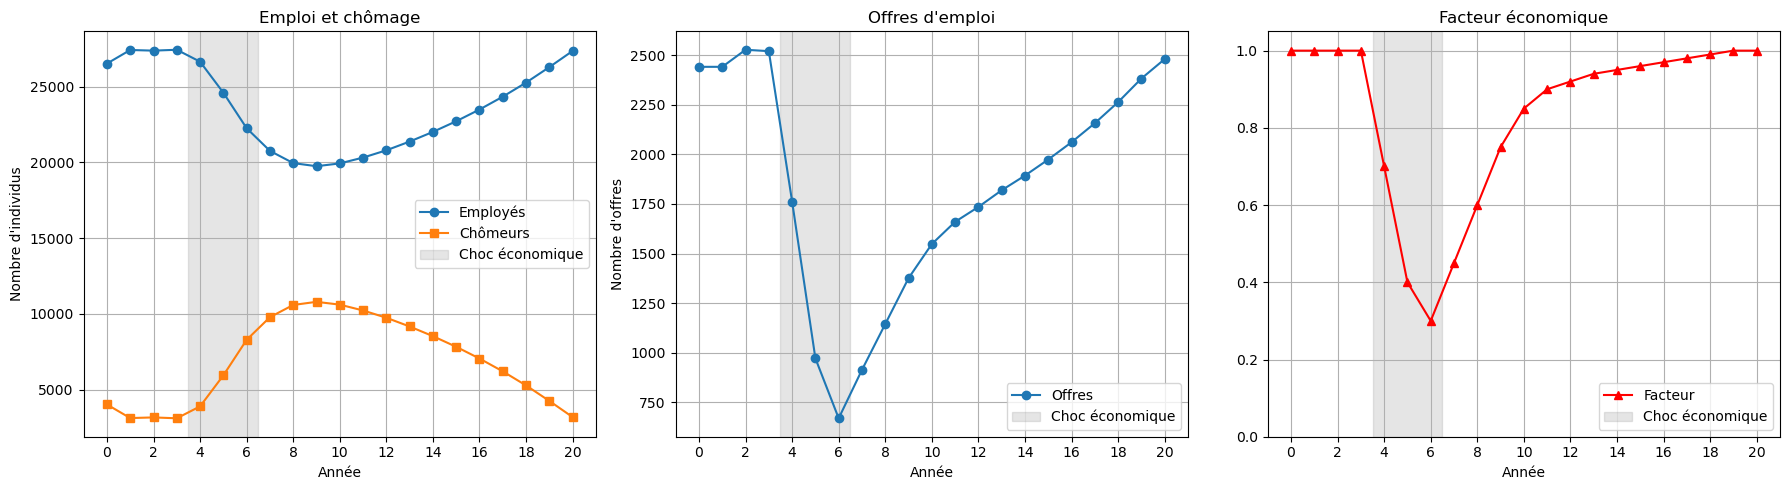

In [22]:
graphe_evolution(historique,FACTEURS_ANNEE)

## Interpretation du graphique

Constat. Pendant les trois premières années, le chômage baisse de 4 018 à environ 3 100 personnes (de 13,2 % à 10,2 % de la population). Avec le choc économique des années 4 à 6, les offres d’emploi s’effondrent, de 2 520 à 670 (−73 %). Le chômage culmine à 10 791 personnes en année 9 (35,3 %), puis redescend progressivement jusqu’à 3 184 en année 20 (10,4 %).

Mécanisme. Le pic de chômage survient en année 9, soit trois ans après le creux du facteur économique (année 6). Ce décalage s’explique par la comparaison entre départs et embauches : en année 9, le taux de départ (7,5 %) reste supérieur au nombre d’offres rapporté aux employés (environ 6,9 %), donc l’emploi continue de baisser. À partir de l’année 10, les offres dépassent les départs et l’emploi repart à la hausse. La reprise est aussi plus lente que la crise : le chômage met 6 ans à monter, mais 11 ans à revenir à son niveau initial.

Limite. Un taux de chômage de 35 % est bien supérieur à ce qu’on observe en réalité. Le modèle amplifie les chocs, car un même facteur réduit à la fois les offres et augmente les départs, sans mécanisme de soutien à l’emploi comme le chômage partiel.


## Répartition de l’emploi par secteur

Cette fonction permet de montrer comment les emplois sont répartis entre les différents secteurs d’activité pour une année donnée.

Le graphique permet de voir rapidement quel secteur emploie le plus et comment les emplois se partagent entre l’agriculture, l’industrie, la construction et le tertiaire


In [23]:
def camembert_secteur(historique, annee):
    """Répartition des emplois par secteur pour une année donnée."""
    secteurs = {"AGR": "Agriculture", "IND": "Industrie",
                "CON": "Construction", "TER": "Tertiaire"}
    effectifs = [historique["emplois_par_secteur"][s][annee] for s in secteurs]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.pie(effectifs, labels=secteurs.values(), autopct="%1.1f%%", startangle=90)
    ax.set_title(f"Répartition des emplois par secteur, année {annee}")
    plt.show()

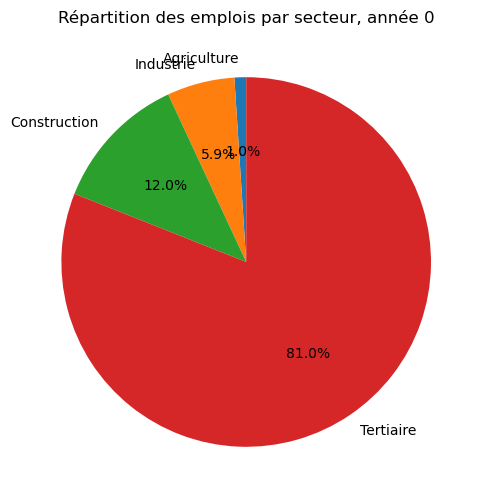

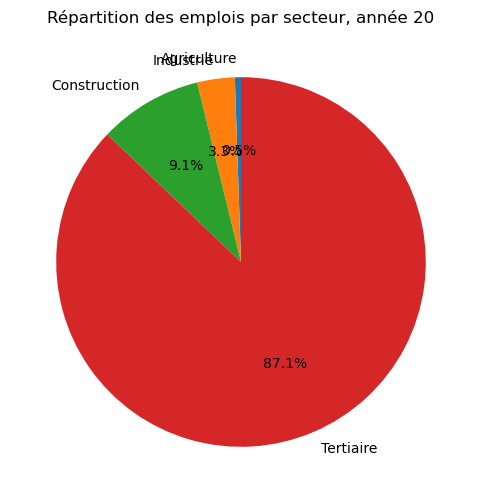

In [33]:
camembert_secteur(historique, 0)
camembert_secteur(historique, 20)

## Interpretation du graphique

Constat. Le tertiaire, déjà majoritaire au départ (81,0 % des emplois), représente 87,1 % des emplois en année 20. La part de la construction passe de 12,0 % à 9,1 %, celle de l’industrie de 5,9 % à 3,3 %, et celle de l’agriculture de 1,0 % à 0,5 %.

Mécanisme. Ce mouvement de tertiarisation vient des paramètres du modèle : le tertiaire ouvre chaque année 10 % de son effectif en offres, bien plus que les autres secteurs.

Limite. Cette concentration est une conséquence mécanique des coefficients choisis, pas une prévision économique.


## 🔹 Évolution du nombre de salariés d’une entreprise

Cette fonction permet de visualiser l’**évolution du nombre de salariés** d’une entreprise donnée au cours de la simulation.

À partir des données stockées dans l’historique des entreprises, elle trace l’évolution des effectifs de l’entreprise sélectionnée année après année.  
Ce graphique permet d’analyser le comportement individuel d’une entreprise et d’observer l’impact des conditions économiques simulées sur ses effectifs.

La représentation obtenue offre ainsi une **lecture détaillée** de la trajectoire d’une entreprise spécifique au sein du marché du travail simulé.


In [25]:
def evolution_entreprise(historique, historique_entreprises, id_entreprise):
    """Évolution de l'effectif d'une entreprise au cours de la simulation."""
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(historique["annee"], historique_entreprises[id_entreprise]["nbsalarie"], marker="o")
    ax.axvspan(3.5, 6.5, color="grey", alpha=0.2)
    ax.set_title(f"Effectif de {id_entreprise} au cours de la simulation")
    ax.set_xlabel("Année")
    ax.set_ylabel("Nombre de salariés")
    ax.grid(True)
    plt.show()

['InVivo', 'Groupe Avril', 'Terrena', 'Limagrain', 'Soufflet Agriculture', 'Tereos', 'Agrial', 'Bonduelle', 'Coopérative Océalia', 'AgroNova', 'Vinci Construction', 'Bouygues Travaux Publics', 'Eiffage Construction', 'Colas', 'Spie Batignolles', 'Léon Grosse', 'NGE', 'Fayat', 'Demathieu Bard', 'Construxia', 'Renault', 'Stellantis', 'Airbus', 'Safran', 'ArcelorMittal', 'Michelin', 'Saint-Gobain', 'TotalEnergies', 'Alstom', 'Mécafrance Industrie', 'BNP Paribas', 'Société Générale', 'Capgemini', 'Orange', 'Accor', 'Carrefour', 'La Poste', 'AXA', 'Dassault Systèmes', 'DataLink Consulting']


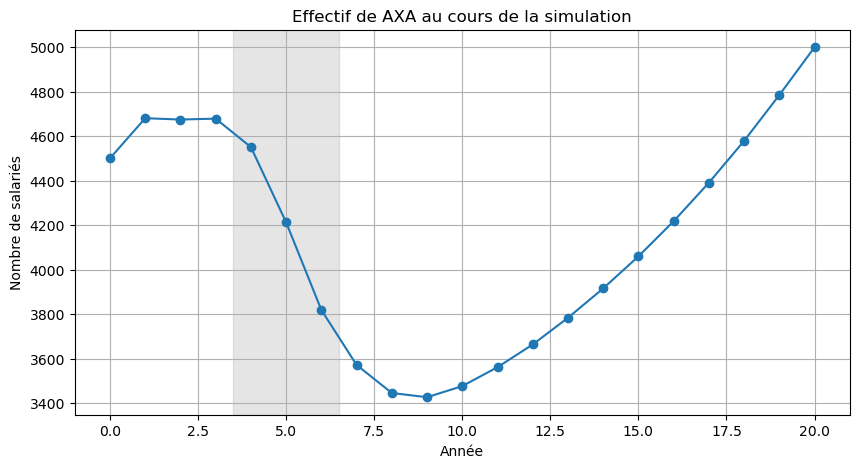

In [26]:
print([e['id']for e in dataEntr])
evolution_entreprise(historique,historique_entreprises,"AXA")

## Interpretation du graphique

Constat. L’effectif d’AXA augmente légèrement en début de simulation (de 4 500 à environ 4 680), puis chute pendant la crise jusqu’à 3 426 salariés en année 9 (−27 % par rapport à l’année 3). Il se redresse ensuite et atteint 4 999 salariés en année 20, soit 11 % de plus qu’au départ.

Mécanisme. AXA suit la dynamique du secteur tertiaire, dont elle est la plus grande entreprise. Son taux d’ouverture de postes élevé (10 %) lui permet de dépasser son effectif initial une fois la conjoncture revenue à la normale.

Limite. Toutes les entreprises d’un même secteur suivent les mêmes règles : le modèle ne distingue pas la stratégie ou la santé financière propre à chaque entreprise


## Évolution de l’emploi par secteur

Cette fonction permet de visualiser l’**évolution du nombre d’emplois dans chaque secteur d’activité** au cours de la simulation.

Les courbes obtenues permettent de comparer les dynamiques sectorielles et d’observer l’impact des conditions économiques sur l’emploi dans chaque secteur.


In [27]:
def courbes_secteurs(historique):
    """Évolution de l'emploi par secteur, en indice base 100 à l'année 0."""
    noms = {"AGR": "Agriculture", "IND": "Industrie",
            "CON": "Construction", "TER": "Tertiaire"}
    fig, ax = plt.subplots(figsize=(10, 6))
    for sec, nom in noms.items():
        serie = historique["emplois_par_secteur"][sec]
        ax.plot(historique["annee"], [100 * v / serie[0] for v in serie], label=nom)
    ax.axhline(100, color="black", linewidth=0.8)
    ax.axvspan(3.5, 6.5, color="grey", alpha=0.2, label="Choc économique")
    ax.set_title("Évolution de l'emploi par secteur (base 100 à l'année 0)")
    ax.set_xlabel("Année")
    ax.set_ylabel("Indice")
    ax.legend()
    ax.grid(True)
    plt.show()


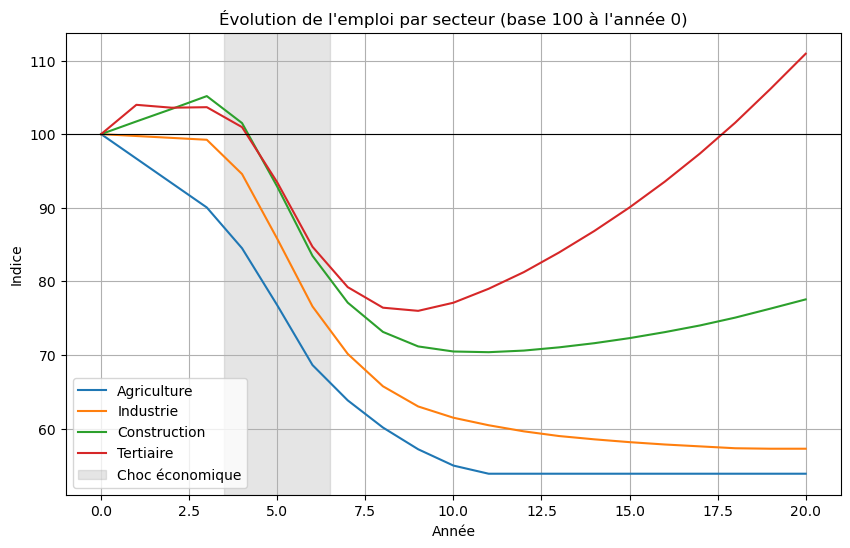

In [28]:
courbes_secteurs(historique)

## Interpretation du graphique

Constat. Les secteurs évoluent très différemment sur 20 ans :

le tertiaire progresse de 11 %, après une chute de 27 % pendant la crise ;
la construction perd 22 %, avec un creux de −33 % en année 11 ;
l’industrie perd 43 %, sans reprise ;
l’agriculture perd 46 %, et décline même pendant les années normales.

Mécanisme. Tous les secteurs subissent le même facteur économique. Leurs différences viennent de l’écart entre leur taux d’ouverture de postes et le taux de départ de base (5 %) :

le tertiaire (10 %) et la construction (7 %) ouvrent plus de postes qu’ils n’en perdent en temps normal, et peuvent donc se reconstruire ;
l’industrie (5 %) ouvre au mieux autant de postes qu’elle en perd : elle ne peut pas récupérer ses pertes ;
l’agriculture (3 %) perd structurellement des emplois, même sans crise.

Limite. À partir de l’année 11, l’emploi agricole reste figé à 146. Les entreprises agricoles comptent alors une quinzaine de salariés, et l’arrondi à l’entier inférieur (int) donne 0 offre et 0 départ. C’est un effet de troncature sur les petits effectifs, et non un phénomène économique. Utiliser un tirage aléatoire (par exemple une loi binomiale) à la place de l’arrondi corrigerait ce biais.



## Suivi du parcours professionnel d’une personne

Cette fonction permet de visualiser le **parcours professionnel d’une personne** identifiée par son identifiant au cours de la simulation.

Deux graphiques sont affichés côte à côte :
- l’évolution du **nombre d’années d’expérience professionnelle**,
- l’évolution du **statut d’emploi** (employé ou non employé).

Les résultats obtenus peuvent **varier d’une exécution à l’autre**, car la simulation repose sur des mécanismes aléatoires.  
Le graphique reflète donc une **réalisation possible** du parcours professionnel d’une personne sur les 20 années simulées.


In [29]:
def afficher_evolution_personne(historique_personne, id_personne):
    annees = historique_personne["annee"]
    
    plt.figure(figsize=(14, 6))

    # Graphique 1 expérience
    plt.subplot(1, 2, 1)
    plt.plot(annees, historique_personne["experience"], marker='o')
    plt.title("Évolution de l'expérience")
    plt.xlabel("Année")
    plt.ylabel("Années d'expérience")
    plt.xticks(annees)
    plt.yticks(historique_personne["experience"])

    # Graphique 2 :statut emploi
    plt.subplot(1, 2, 2)
    statut = historique_personne["employe"]
    couleurs = ["green" if s == 1 else "red" for s in statut]
    plt.scatter(annees, statut, c=couleurs, s=100)
    plt.yticks([0, 1], ["Non employé", "Employé"])
    plt.title("Évolution du statut d'emploi")
    plt.xlabel("Année")
    plt.xticks(annees)
    plt.grid(True)
    

    plt.suptitle(f"Parcours professionnel de la personne {id_personne}")
    plt.tight_layout()
    plt.show()


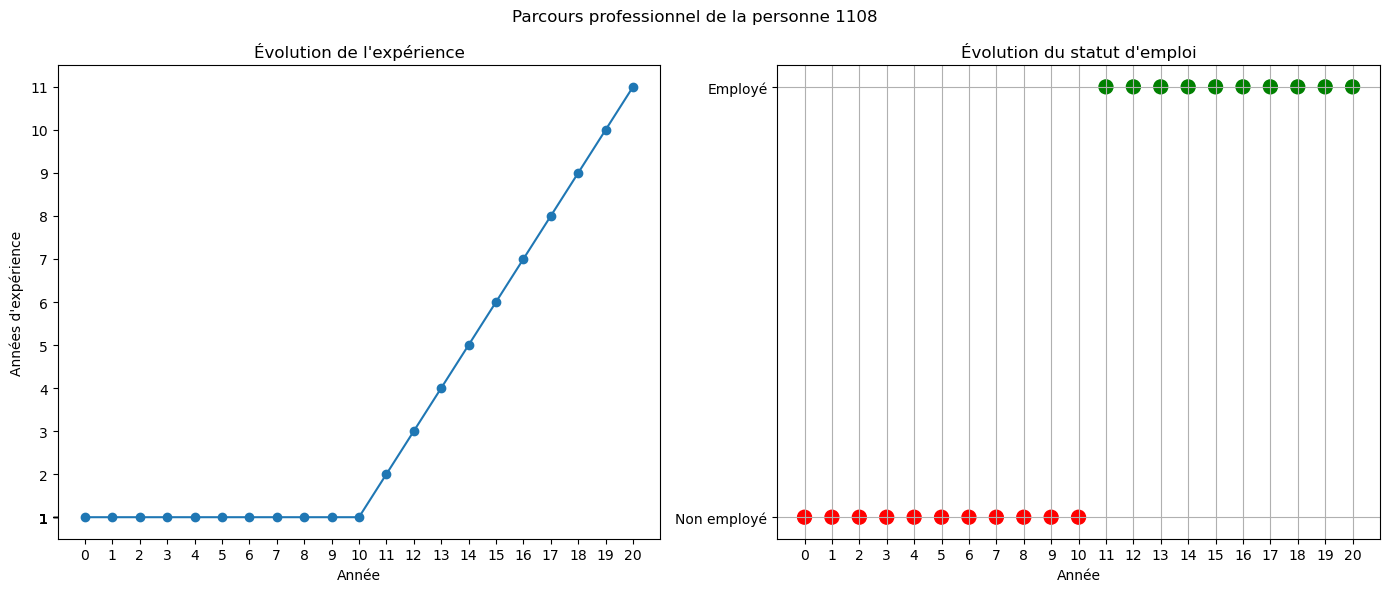

In [30]:
afficher_evolution_personne(historique_personne,personne_choisi)

In [31]:
print(historique_personne["entreprise"])

['Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Aucune', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis', 'Stellantis']


## Interpretation du graphique

La personne 1108 est sans emploi au départ, avec 1 an d’expérience. Elle reste au chômage pendant 11 ans, y compris pendant les années favorables, puis elle est recrutée par Stellantis en année 11. Son expérience reste bloquée à 1 an pendant toute sa période de chômage, puis augmente d’un an chaque année jusqu’à atteindre 11 ans en année 20.

Mécanisme. Avec 1 an d’expérience, elle n’a accès qu’aux offres de l’agriculture et de l’industrie, qui sont les secteurs qui recrutent le moins. Les offres du tertiaire et de la construction, les plus nombreuses, exigent au moins 2 ou 3 ans d’expérience. Le modèle reproduit ainsi un cercle vicieux : sans emploi, on ne gagne pas d’expérience, et sans expérience, on accède à peu d’offres.

Limite. Il s’agit d’une seule trajectoire, qui dépend du tirage aléatoire. Pour tirer des conclusions, il faudrait étudier la durée moyenne du chômage sur toute la population.

## Conclusion
Cette simulation reproduit les grandes dynamiques d’un choc économique : une chute rapide de l’emploi, un pic de chômage décalé de trois ans par rapport au creux de la conjoncture, et une reprise lente. Elle montre aussi que les secteurs réagissent différemment selon leur capacité à recruter, et que le manque d’expérience peut enfermer durablement certaines personnes dans le chômage. Ses principales limites sont l’amplification des chocs, l’arrondi sur les petits effectifs et l’analyse d’une seule réalisation aléatoire. Une suite naturelle serait de lancer la simulation plusieurs centaines de fois (méthode de Monte-Carlo) pour estimer la distribution du taux de chômage